Import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Impostiamo lo stile dei grafici
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None) # Per vedere tutte le colonne
print("Librerie importate con successo")

Librerie importate con successo


Entità di base

In [2]:
df_airlines = pd.read_csv('../data/airlines.csv')
df_airports = pd.read_csv('../data/airports.csv')

print(f"Numero di compagnie aeree: {df_airlines.shape[0]}")
print(f"Numero di aeroporti: {df_airports.shape[0]}\n")

display(df_airlines.head(3))
display(df_airports.head(3))

Numero di compagnie aeree: 14
Numero di aeroporti: 322



,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919


Dataset principale

In [3]:
print("Caricamento in corso...")
df_flights = pd.read_csv('../data/flights.csv', low_memory=False)

print(f"Caricamento completato - Righe: {df_flights.shape[0]}, Colonne: {df_flights.shape[1]}")
display(df_flights.head(5))

Caricamento in corso...
Caricamento completato - Righe: 5819079, Colonne: 31


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,2354.0,-11.0,21.0,15.0,205.0,194.0,169.0,1448,404.0,4.0,430,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,2.0,-8.0,12.0,14.0,280.0,279.0,263.0,2330,737.0,4.0,750,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,18.0,-2.0,16.0,34.0,286.0,293.0,266.0,2296,800.0,11.0,806,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,15.0,-5.0,15.0,30.0,285.0,281.0,258.0,2342,748.0,8.0,805,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,24.0,-1.0,11.0,35.0,235.0,215.0,199.0,1448,254.0,5.0,320,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Analisi valori nulli

In [4]:
print("--- ANALISI VALORI NULLI ---")
# Calcoliamo la percentuale di valori nulli per ogni colonna
null_percentages = (df_flights.isnull().sum() / len(df_flights)) * 100
missing_data = null_percentages[null_percentages > 0].sort_values(ascending=False)

print(missing_data)

--- ANALISI VALORI NULLI ---
CANCELLATION_REASON    98.455357
WEATHER_DELAY          81.724960
LATE_AIRCRAFT_DELAY    81.724960
AIRLINE_DELAY          81.724960
SECURITY_DELAY         81.724960
AIR_SYSTEM_DELAY       81.724960
ELAPSED_TIME            1.805629
AIR_TIME                1.805629
ARRIVAL_DELAY           1.805629
ARRIVAL_TIME            1.589822
TAXI_IN                 1.589822
WHEELS_ON               1.589822
WHEELS_OFF              1.530259
TAXI_OUT                1.530259
DEPARTURE_TIME          1.480526
DEPARTURE_DELAY         1.480526
TAIL_NUMBER             0.252978
SCHEDULED_TIME          0.000103
dtype: float64


Query di test (ritardio medio)

C:\Users\nicde\AppData\Local\Temp\ipykernel_3524\2819442019.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=delay_df, x='DEPARTURE_DELAY', y='AIRLINE_y', palette='viridis')


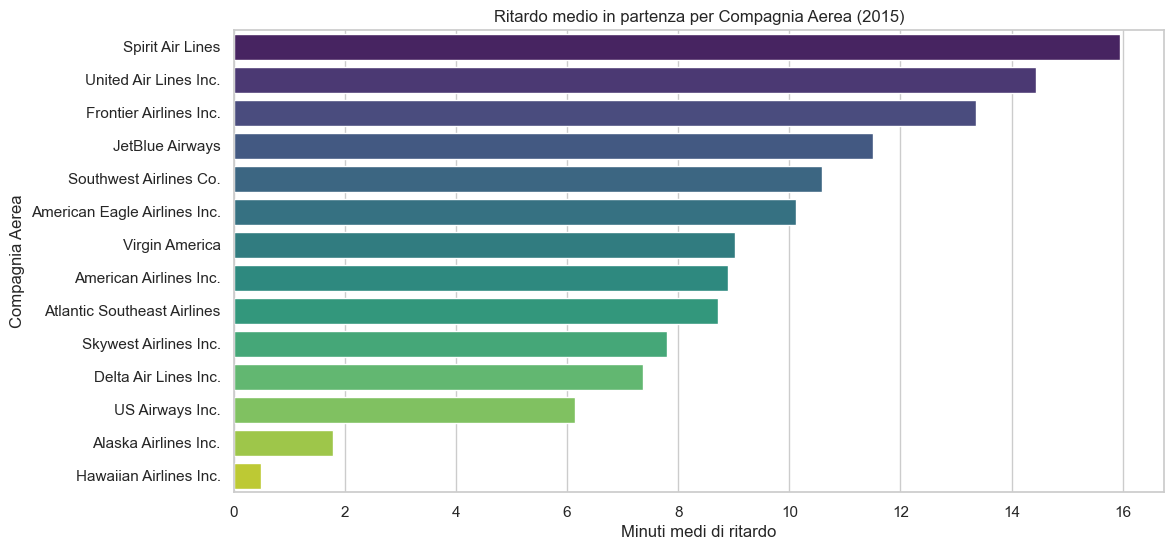

In [5]:
# Raggruppamento per compagnia e calcolo del ritardo medio
delay_by_airline = df_flights.groupby('AIRLINE')['DEPARTURE_DELAY'].mean().sort_values(ascending=False)

# Unione con il DataFrame delle compagnie aeree per ottenere i nomi completi
delay_df = delay_by_airline.reset_index().merge(df_airlines, left_on='AIRLINE', right_on='IATA_CODE')

plt.figure(figsize=(12, 6))
sns.barplot(data=delay_df, x='DEPARTURE_DELAY', y='AIRLINE_y', palette='viridis')
plt.title('Ritardo medio in partenza per Compagnia Aerea (2015)')
plt.xlabel('Minuti medi di ritardo')
plt.ylabel('Compagnia Aerea')
plt.show()

Verifica integrità referenziale

In [6]:
print("--- TEST INTEGRITÀ REFERENZIALE ---")

# TEST AEROPORTI (Foreign Keys: ORIGIN_AIRPORT, DESTINATION_AIRPORT)
airports_in_anagrafica = set(df_airports['IATA_CODE'].unique())
origins_in_flights = set(df_flights['ORIGIN_AIRPORT'].unique())
destinations_in_flights = set(df_flights['DESTINATION_AIRPORT'].unique())

missing_origins = origins_in_flights - airports_in_anagrafica
missing_destinations = destinations_in_flights - airports_in_anagrafica

print(f"Aeroporti di partenza non presenti in airports.csv: {len(missing_origins)}")
print(f"Aeroporti di arrivo non presenti in airports.csv: {len(missing_destinations)}")

if len(missing_origins) > 0:
    print(f"Esempio di aeroporti mancanti: {list(missing_origins)[:5]}\n")

# TEST COMPAGNIE AEREE (Foreign Key: AIRLINE)
airlines_in_anagrafica = set(df_airlines['IATA_CODE'].unique())
airlines_in_flights = set(df_flights['AIRLINE'].unique())

missing_airlines = airlines_in_flights - airlines_in_anagrafica

print(f"Compagnie aeree nei voli non presenti in airlines.csv: {len(missing_airlines)}")

if len(missing_airlines) > 0:
    print(f"Esempio di compagnie mancanti: {list(missing_airlines)[:5]}")
else:
    print("Nessuna anomalia")

--- TEST INTEGRITÀ REFERENZIALE ---
Aeroporti di partenza non presenti in airports.csv: 306
Aeroporti di arrivo non presenti in airports.csv: 307
Esempio di aeroporti mancanti: ['10434', '10155', '13158', '14893', '11630']

Compagnie aeree nei voli non presenti in airlines.csv: 0
Nessuna anomalia


Analisi dell'anomalia

--- INDAGINE DELL'ANOMALIA ---
Lunghezze dei codici nell'anagrafica ufficiale (airports.csv): [3]
Lunghezze dei codici nei voli (flights.csv): [3 5]

Distribuzione delle lunghezze nei voli:
ORIGIN_AIRPORT
3    5332914
5     486165
Name: count, dtype: int64


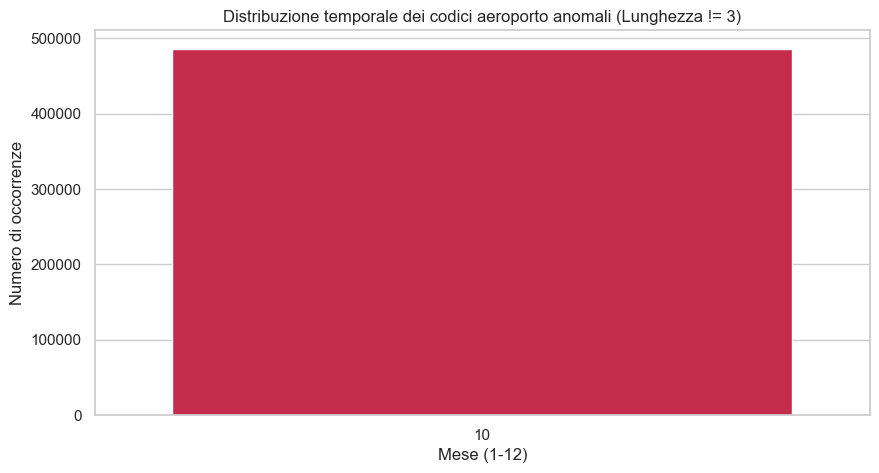

In [7]:
print("--- INDAGINE DELL'ANOMALIA ---")

# Verifica della lunghezza dei codici aeroportuali
airport_lengths_ref = df_airports['IATA_CODE'].dropna().astype(str).map(len).unique()
print(f"Lunghezze dei codici nell'anagrafica ufficiale (airports.csv): {airport_lengths_ref}")

# Verifica della lunghezza dei codici aeroportuali nei voli
airport_lengths_flights = df_flights['ORIGIN_AIRPORT'].dropna().astype(str).map(len).unique()
print(f"Lunghezze dei codici nei voli (flights.csv): {airport_lengths_flights}")

# Calcolo della distribuzione delle lunghezze dei codici aeroportuali nei voli
lengths_distribution = df_flights['ORIGIN_AIRPORT'].astype(str).map(len).value_counts()
print("\nDistribuzione delle lunghezze nei voli:")
print(lengths_distribution)

# Isolamento record che violano lo standard
standard_len = airport_lengths_ref[0] 
df_flights['code_len'] = df_flights['ORIGIN_AIRPORT'].astype(str).map(len)

df_anomalies = df_flights[df_flights['code_len'] != standard_len]
anomaly_by_month = df_anomalies.groupby('MONTH').size()

# Grafico della distribuzione
plt.figure(figsize=(10, 5))
sns.barplot(x=anomaly_by_month.index, y=anomaly_by_month.values, color='crimson')
plt.title(f'Distribuzione temporale dei codici aeroporto anomali (Lunghezza != {standard_len})')
plt.xlabel('Mese (1-12)')
plt.ylabel('Numero di occorrenze')
plt.show()

Dimensionamento colonne testuali

In [8]:
print("--- DIMENSIONAMENTO COLONNE TESTUALI ---")
colonne_testuali = ['TAIL_NUMBER', 'CANCELLATION_REASON', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'AIRLINE']

for col in colonne_testuali:
    max_len = df_flights[col].dropna().astype(str).map(len).max()
    print(f"Dimensione colonna {col}: VARCHAR({max_len})")

--- DIMENSIONAMENTO COLONNE TESTUALI ---
Dimensione colonna TAIL_NUMBER: VARCHAR(6)
Dimensione colonna CANCELLATION_REASON: VARCHAR(1)
Dimensione colonna ORIGIN_AIRPORT: VARCHAR(5)
Dimensione colonna DESTINATION_AIRPORT: VARCHAR(5)
Dimensione colonna AIRLINE: VARCHAR(2)


Analisi rotte più trafficate

--- LE ROTTE PIÙ TRAFFICATE ---
ROUTE
SFO -> LAX    13744
LAX -> SFO    13457
JFK -> LAX    12016
LAX -> JFK    12015
LAS -> LAX     9715
Name: count, dtype: int64


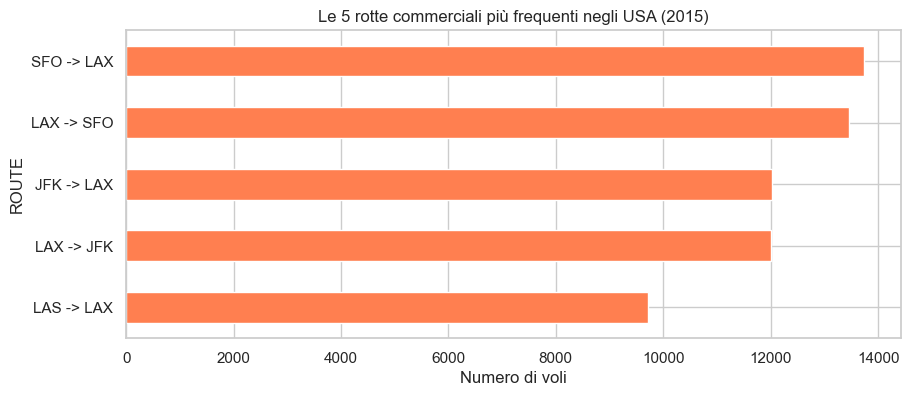

In [9]:
print("--- LE ROTTE PIÙ TRAFFICATE ---")

# Creazione nuova colonna che unisce origine e destinazione
df_flights['ROUTE'] = df_flights['ORIGIN_AIRPORT'] + " -> " + df_flights['DESTINATION_AIRPORT']

top_routes = df_flights['ROUTE'].value_counts().head(5)
print(top_routes)

# Grafico delle top rotte
plt.figure(figsize=(10, 4))
top_routes.plot(kind='barh', color='coral')
plt.title('Le 5 rotte commerciali più frequenti negli USA (2015)')
plt.gca().invert_yaxis()
plt.xlabel('Numero di voli')
plt.show()

Traffico per hub

--- ANALISI DEL TRAFFICO PER HUB ---


C:\Users\nicde\AppData\Local\Temp\ipykernel_3524\2335182887.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=flights_per_airport.values, y=flights_per_airport.index, palette='magma')


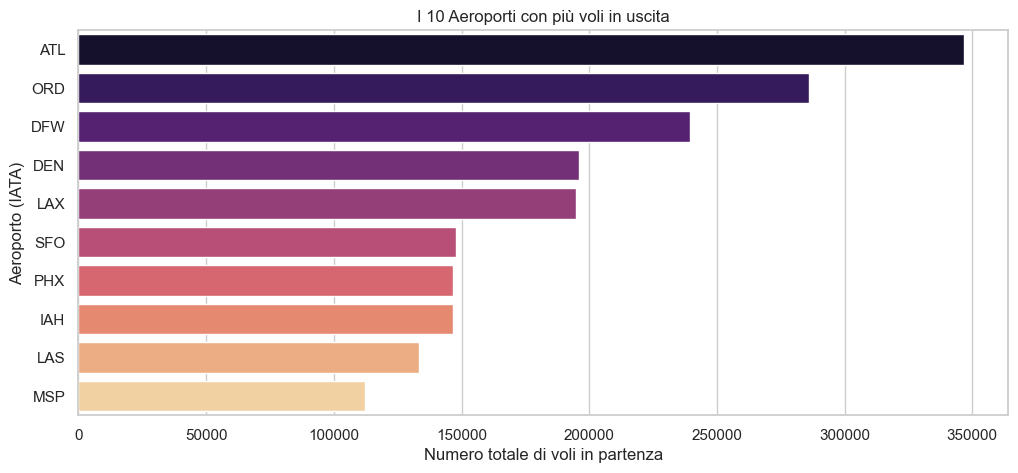

In [10]:
print("--- ANALISI DEL TRAFFICO PER HUB ---")

# Conteggio dei voli in uscita per aeroporto
flights_per_airport = df_flights['ORIGIN_AIRPORT'].value_counts().head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=flights_per_airport.values, y=flights_per_airport.index, palette='magma')
plt.title('I 10 Aeroporti con più voli in uscita')
plt.xlabel('Numero totale di voli in partenza')
plt.ylabel('Aeroporto (IATA)')
plt.show()